In [5]:
import sys
print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")

/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/.venv/bin/python
Environment ready!


In [6]:
import os
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import torch
import torchvision

In [12]:

# for macos user 
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Selected device:", device)


MPS available: True
Selected device: mps


# Data Exploration


In [36]:

from torchvision.datasets import ImageFolder
from pathlib import Path

data_train = Path("/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train")

dataset = ImageFolder(root=data_train)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)


Total images: 155515
Classes: ['AI', 'Human']
Class mapping: {'AI': 0, 'Human': 1}


In [35]:
classes = ["Human", "AI"]
counts = [nb_human_images, nb_ia_images]
total_images = sum(counts)
percentages = [count / total_images * 100 for count in counts]
for class_name, count, percentage in zip(classes, counts, percentages):
    print(f"{class_name}: {count} images ({percentage:.2f}%)")



Human: 50096 images (32.21%)
AI: 105419 images (67.79%)


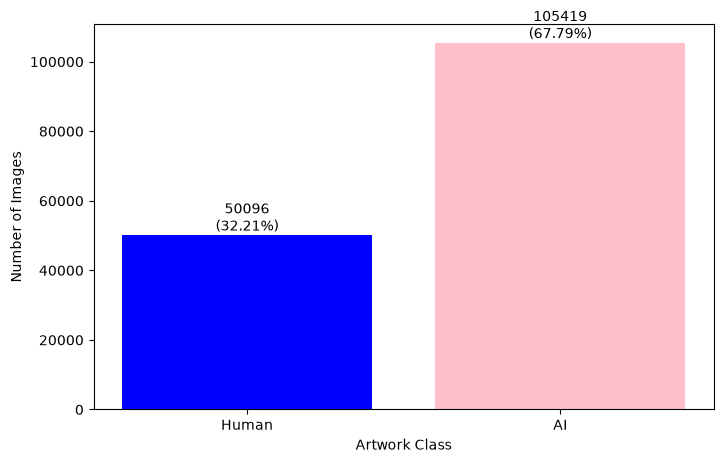

In [37]:
plt.figure(figsize=(8, 5))
bars = plt.bar(classes, counts, color=['blue', 'pink'])
for bar,count,percentage in zip(bars, counts, percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, 
    bar.get_height(), 
    f'{count}\n({percentage:.2f}%)',
    ha='center',
    va='bottom')
plt.xlabel("Artwork Class")
plt.ylabel("Number of Images")

plt.show()


### class distribution analysis
here we see that the dataset is moderatlely imbalanced it may introduce biais toward the majority class =AI class so it should be considered during the model trainng and evaluation 

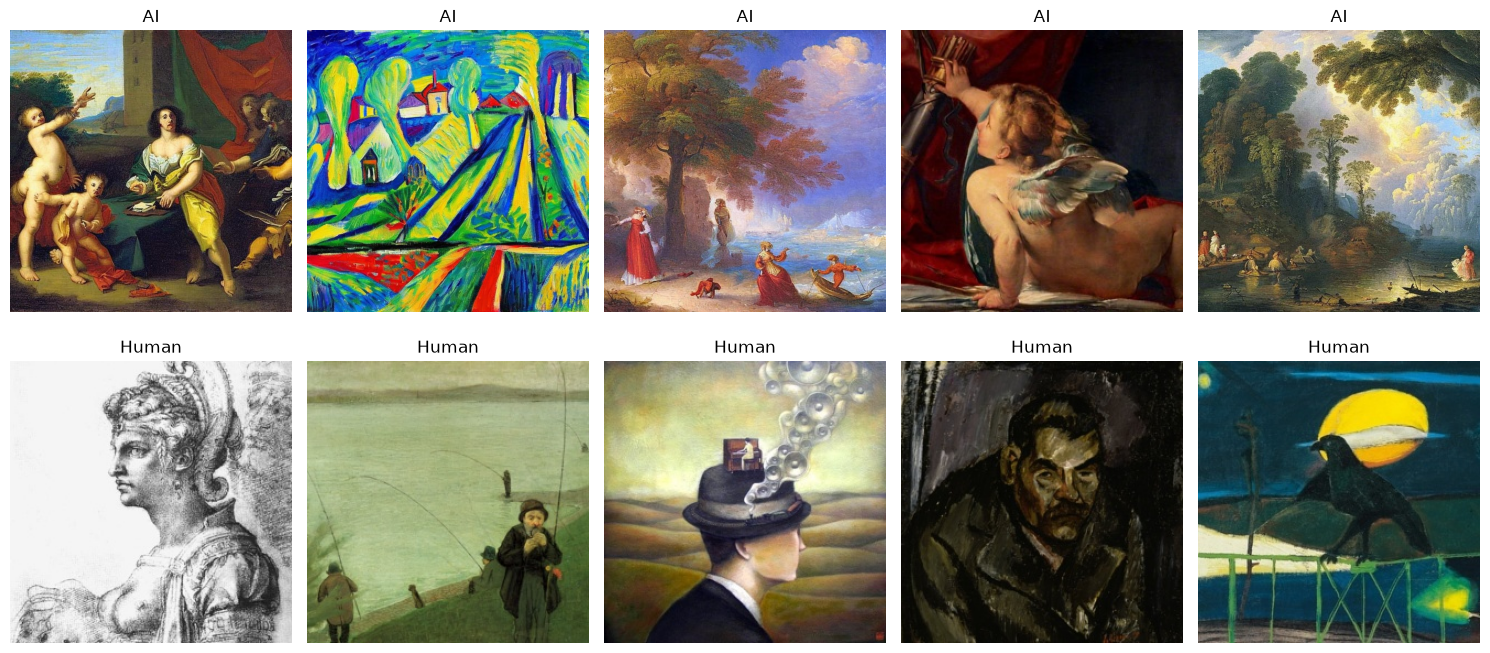

In [38]:

import matplotlib.pyplot as plt
import random

random.seed(42)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(dataset.classes):

    # Get indices of images belonging to this class
    indices = [
        i for i, label in enumerate(dataset.targets)
        if label == dataset.class_to_idx[class_name]
    ]

    # Select 5 random images
    samples = random.sample(indices, 5)

    for col, idx in enumerate(samples):
        img, label = dataset[idx]

        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()


In [ ]:

import random
import pandas as pd
from PIL import Image

random.seed(42)

# Select 1000 images per class
selected_samples = []

for class_idx in range(len(dataset.classes)):
    class_samples = [
        sample for sample in dataset.samples
        if sample[1] == class_idx
    ]

    selected_samples.extend(
        random.sample(class_samples, min(1000, len(class_samples)))
    )

# Extract image properties
image_info = []

for path, label in selected_samples:
    try:
        with Image.open(path) as img:
            width, height = img.size

            image_info.append({
                "Class": dataset.classes[label],
                "Width": width,
                "Height": height,
                "Resolution": f"{width}x{height}",
                "Aspect_Ratio": width / height,
                "Color_Mode": img.mode
            })

    except (OSError, ValueError) as e:
        print(f"Could not read {path}: {e}")

# Create DataFrame
df_images = pd.DataFrame(image_info)

# Resolution distribution
print("Resolution distribution by class:")
display(pd.crosstab(
    df_images["Class"],
    df_images["Resolution"]
))

# Aspect ratio statistics
print("Aspect ratio statistics by class:")
display(
    df_images.groupby("Class")["Aspect_Ratio"]
    .describe()
    .round(3)
)

# Percentage of square images
print("Percentage of square images:")
display(
    df_images.assign(
        Is_Square=df_images["Width"] == df_images["Height"]
    )
    .groupby("Class")["Is_Square"]
    .mean()
    .mul(100)
    .round(2)
)

# Color mode distribution
print("Color mode distribution by class:")
display(pd.crosstab(
    df_images["Class"],
    df_images["Color_Mode"]
))


Resolution distribution by class:


Resolution,256x256,768x768
Class,,
AI,518,482
Human,959,41


Aspect ratio statistics by class:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
AI,1000.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Human,1000.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


Percentage of square images:


Class
AI       100.0
Human    100.0
Name: Is_Square, dtype: float64

Color mode distribution by class:


Color_Mode,RGB
Class,
AI,1000
Human,1000


### Image Dimensions and Aspect Ratio Analysis

The analysis of 2,000 images (1,000 per class) shows that **100% of the sampled images have an aspect ratio of 1.0**, meaning that all images are square.

However, the image resolution distribution differs between classes:

- **Human:** 95.9% of images are 256 × 256 pixels.
- **AI:** 51.8% are 256 × 256 pixels and 48.2% are 768 × 768 pixels.

These findings suggest that image resolution may act as a spurious feature for classification.

To standardize the input dimensions, all images will be resized to **256 × 256 pixels** during preprocessing. Since all sampled images are square, this transformation will preserve their aspect ratios.



j'ai pas choisis 768 × 768, car  j'agrandirai artificiellement presque toutes les images Human !!

In [57]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


Check if there is duplicated images 

In [59]:

import hashlib
from collections import defaultdict

def image_hash(filepath):
    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

hash_groups = defaultdict(list)

for path, label in tqdm(dataset.samples, desc="Checking duplicates"):
    if path in corrupted_images:
        continue

    hash_groups[image_hash(path)].append((path, label))

duplicates = {
    hash_value: files
    for hash_value, files in hash_groups.items()
    if len(files) > 1
}

print("Duplicate groups:", len(duplicates))
print("Extra duplicate files:", sum(len(files) - 1 for files in duplicates.values()))

# Display first 5 duplicate groups
for files in list(duplicates.values())[:5]:
    print(files)


Checking duplicates: 100%|██████████| 155515/155515 [00:40<00:00, 3873.61it/s]


Duplicate groups: 5
Extra duplicate files: 5
[('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_019787.jpg', 0), ('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_172782.jpg', 0)]
[('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_020373.jpg', 0), ('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_103434.jpg', 0)]
[('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_020451.jpg', 0), ('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_113369.jpg', 0)]
[('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_048610.jpg', 0), ('/Users/mariaboubekeur/Desktop/M2/DeepLearning/Automatic_classification_ArtWorks/data/train/AI/img_176155.jpg', 0)]
[('/Users/maria

Exact duplicate detection was conducted using SHA-256 hashing across all 155,515 training images.

Five duplicate groups were identified, corresponding to five redundant files

To avoid potential data leakage, only one image from each duplicate group will be retained before splitting the dataset.

In [60]:

import pandas as pd

# Check for conflicting labels
conflicting_groups = [
    files for files in hash_groups.values()
    if len({label for path, label in files}) > 1
]

if conflicting_groups:
    raise ValueError("Conflicting labels detected!")

# Keep one image per unique hash
clean_samples = [files[0] for files in hash_groups.values()]

# Create clean DataFrame
df_clean = pd.DataFrame(
    clean_samples,
    columns=["filepath", "label"]
)

df_clean["class_name"] = df_clean["label"].map(
    {i: name for i, name in enumerate(dataset.classes)}
)

print("Original dataset:", len(dataset))
print("Clean dataset:", len(df_clean))
print("Duplicates removed:", len(dataset) - len(df_clean))


Original dataset: 155515
Clean dataset: 155510
Duplicates removed: 5


SPLIT TRAIN TEST VALIDATION 

In [61]:

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining class distribution:")
print((train_df["class_name"].value_counts(normalize=True) * 100).round(2))

print("\nValidation class distribution:")
print((val_df["class_name"].value_counts(normalize=True) * 100).round(2))


Training images: 124408
Validation images: 31102

Training class distribution:
class_name
AI       67.79
Human    32.21
Name: proportion, dtype: float64

Validation class distribution:
class_name
AI       67.79
Human    32.21
Name: proportion, dtype: float64


# Data Preprocessing


In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# CNN Architecture
